Kalshi vs pro bookmakers (all leagues with football-data.co.uk coverage)

Inputs:
- `results/full/<league>/analysis_ready.csv` – produced by the 9-league run (Kalshi quotes 1d before)
- `data/<league>/<league>_full_candlesticks.csv` and `kalshi_<league>_markets.pkl` 
- `data/bookmakers/<league>/*.csv` – football-data.co.uk files downloaded, any nb/league:

| league folder | football-data file | where on the site |
|---|---|---|
| `epl` | `E0` per season | Main leagues → England |
| `laliga` | `SP1` per season | Main leagues → Spain |
| `bundesliga` | `D1` per season | Main leagues → Germany |
| `seriea` | `I1` per season | Main leagues → Italy |
| `ligue1` | `F1` per season | Main leagues → France |
| `eredivisie` | `N1` per season | Main leagues → Netherlands |
| `brasileiro` | `BRA` (all seasons in one file) | Extra leagues → Brazil |
| `ligamx` | `MEX` (all seasons in one file) | Extra leagues → Mexico |

The UEFA CL isn't covered by football-data.co.uk -> leagues w/o a bookmaker folder are skipped

2 timing-matched comparisons: \
(1) at kickoff – bookmaker closing odds vs Kalshi's last hourly quote b4 kickoff \
(2) about a day b4 – bookmaker pre-closing odds vs Kalshi's 1-day quote. Odds become Pr as 1/odds rescaled to sum to 1
(removing the bookmaker margin) \& Kalshi midpoints are rescaled the same way.

Team names matched automatically: a Kalshi team code and its football-data name appear on the same match dates every time,
other teams only occasionally. 

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning) # harmless notice when reading wide odds files

PROJECT = (Path.cwd().parent if Path.cwd().name == "src" else Path.cwd())  # project folder
DATA_ROOT = PROJECT / "data"
RESULTS_ROOT = PROJECT / "results" / "full"
BOOK_ROOT = DATA_ROOT / "bookmakers"  # football-data.co.uk files, 1/league
OUT = PROJECT / "results" / "bookmakers"
OUT.mkdir(parents=True, exist_ok=True)

LEAGUE_NAMES = {"epl": "Premier League", "laliga": "La Liga", "bundesliga": "Bundesliga", "seriea": "Serie A",
                "ligue1": "Ligue 1", "eredivisie": "Eredivisie", "ligamx": "Liga MX", "brasileiro": "Brasileirão"}
LEGS = ["home", "draw", "away"]
FEE_RATE = 0.07   # Kalshi taker fee coeff
B = 1000  # bootstrap repl
SEED = 456
MAX_DATE_GAP_DAYS = 10   # a Kalshi match and a football-data match must be at most this far apart 
MANUAL_NAME_OVERRIDES = { # e.g. {("epl", "NFO"): "Nott'm Forest"} if a printed mapping line is wrong; None = no bookmaker match
    ("eredivisie", "ALM"): None,  # Almere City and FC Den Bosch: 2 Kalshi matches each (2026 play-offs),
    ("eredivisie", "DBO"): None,  # not in the Eredivisie file, so they can't be matched
}

ODDS_SOURCES = {   # label: (closing cols, pre-closing cols), in order of pref
    "Pinnacle": (["PSCH", "PSCD", "PSCA"], ["PSH", "PSD", "PSA"]),
    "market average": (["AvgCH", "AvgCD", "AvgCA"], ["AvgH", "AvgD", "AvgA"]),
    "Bet365": (["B365CH", "B365CD", "B365CA"], ["B365H", "B365D", "B365A"]),
    "market maximum": (["MaxCH", "MaxCD", "MaxCA"], ["MaxH", "MaxD", "MaxA"]),
}

import matplotlib as mpl
from cycler import cycler

MIT = {
    "mit_red": "#750014",   
    "red": "#A31F34",   
    "light_red": "#D98C97",   
    "bright_red": "#FF1423",   
    "silver": "#8B959E",   
    "dark_gray":"#626A73",   
    "light_gray": "#B8C2CC",  
    "black": "#212326",  
}
MIT_CYCLE = [MIT[k] for k in ["mit_red", "silver", "light_red", "dark_gray", "red", "light_gray", "black"]]
LEG_COLORS = {"home": MIT["mit_red"], "draw": MIT["silver"], "away": MIT["light_red"]}
HORIZON_COLORS = {"1d": MIT["mit_red"], "7d": MIT["silver"]}

mpl.rcParams.update({
    "axes.prop_cycle": cycler(color=MIT_CYCLE),
    "axes.edgecolor": MIT["dark_gray"], "axes.labelcolor": MIT["black"], "text.color": MIT["black"],
    "xtick.color": MIT["dark_gray"], "ytick.color": MIT["dark_gray"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": MIT["light_gray"], "grid.alpha": 0.6, "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.frameon": False, "legend.fontsize": 9,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
})

FIG_DIR = PROJECT / "images"   # every figure from every notebook goes here
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    # save current fig as PNG and PDF in the project's images/ folder
    for ext in ("png", "pdf"):
        plt.savefig(FIG_DIR / f"{name}.{ext}")

leagues = [l for l in LEAGUE_NAMES if (BOOK_ROOT / l).is_dir() and any((BOOK_ROOT / l).glob("*.csv"))]
print("Leagues with bookmaker files:", leagues or "none – see the table above for what to download")

Leagues with bookmaker files: ['epl', 'laliga', 'bundesliga', 'seriea', 'ligue1', 'eredivisie', 'ligamx', 'brasileiro']


1. Load + standardize files

In [2]:
RENAME = {"HomeTeam": "home_name", "Home": "home_name", "AwayTeam": "away_name", "Away": "away_name",
          "FTR": "ftr", "Res": "ftr"}

def load_bookmaker(league):
    # All football-data CSVs of 1 league, with main-league and extra-league col names unified
    frames = []
    for f in sorted((BOOK_ROOT / league).glob("*.csv")):
        d = pd.read_csv(f, encoding="latin-1")
        d = d.rename(columns={k: v for k, v in RENAME.items() if k in d.columns})
        missing = {"Date", "home_name", "away_name", "ftr"} - set(d.columns)
        assert not missing, f"{f.name}: missing columns {missing}"
        frames.append(d.assign(source_file=f.name))
    bk = pd.concat(frames, ignore_index=True).dropna(subset=["Date", "home_name", "away_name", "ftr"])
    bk["home_name"], bk["away_name"] = bk["home_name"].str.strip(), bk["away_name"].str.strip()
    bk["date"] = pd.to_datetime(bk["Date"], dayfirst=True, format="mixed").dt.normalize()
    n0 = len(bk)
    bk = bk.drop_duplicates(["date", "home_name", "away_name"]).reset_index(drop=True)
    print(f"  bookmaker: {len(bk)} matches from {bk.source_file.nunique()} file(s), "
          f"{bk.date.min().date()} to {bk.date.max().date()} ({n0 - len(bk)} duplicate rows dropped)")
    return bk

def load_kalshi(league):
    # Kalshi matches: 1-day quotes from the 9-league run, + the last pre-kickoff hourly quote from raw candles
    ar = pd.read_csv(RESULTS_ROOT / league / "analysis_ready.csv")
    mk = pd.read_pickle(DATA_ROOT / league / f"kalshi_{league}_markets.pkl")
    candles = pd.read_csv(DATA_ROOT / league / f"{league}_full_candlesticks.csv")
    candles["timestamp"] = pd.to_datetime(candles["timestamp"], utc=True)

    fin = mk[mk["status"] == "finalized"].drop_duplicates("event_ticker").set_index("event_ticker")
    exp_time = pd.to_datetime(fin["expected_expiration_time"], utc=True)
    settle = pd.to_datetime(fin["settlement_ts"], utc=True)

    ev = ar.drop_duplicates("event_ticker")[["event_ticker", "home_code", "away_code", "realized_outcome"]].copy()
    ev["kickoff"] = ev["event_ticker"].map(exp_time) - pd.Timedelta(hours=3)   # E expiration = kickoff + 3h
    ev["kick_date"] = ev["kickoff"].dt.tz_localize(None).dt.normalize()
    names = mk.assign(code=mk["ticker"].str.rsplit("-", n=1).str[-1]).drop_duplicates("code").set_index("code")["yes_sub_title"]
    ev["home_label"], ev["away_label"] = ev["home_code"].map(names), ev["away_code"].map(names)
    ev = ev.set_index("event_ticker")

    # 1-day quotes (normalized midpoints)
    d1 = ar[ar["horizon"] == "1d"].set_index("event_ticker")
    k1 = d1[[f"{l}_midpoint" for l in LEGS]].div(d1[[f"{l}_midpoint" for l in LEGS]].sum(axis=1), axis=0)
    k1.columns = LEGS

    # last pre-kickoff hour in which all 3 legs are quoted
    cutoff = (np.minimum(exp_time, settle) - pd.Timedelta(hours=3))
    c = candles[candles["event_ticker"].isin(ev.index)]
    c = c[c["timestamp"] < c["event_ticker"].map(cutoff)].copy()
    suffix = c["ticker"].str.rsplit("-", n=1).str[-1]
    c["leg"] = np.select([suffix == "TIE", suffix == c["event_ticker"].map(ev["home_code"]),
                          suffix == c["event_ticker"].map(ev["away_code"])], ["draw", "home", "away"], "UNKNOWN")
    c = c[c["leg"] != "UNKNOWN"]
    c = c[c.groupby(["event_ticker", "timestamp"])["leg"].transform("nunique") == 3]
    c = c[c["timestamp"] == c.groupby("event_ticker")["timestamp"].transform("max")]
    mid = ((c["yes_bid"] + c["yes_ask"]) / 2).round(4)
    kc = c.assign(mid=mid).pivot(index="event_ticker", columns="leg", values="mid")[LEGS]
    kc = kc.div(kc.sum(axis=1), axis=0)
    asks = c.pivot(index="event_ticker", columns="leg", values="yes_ask")[LEGS]
    hours_before = (ev["kickoff"] - c.groupby("event_ticker")["timestamp"].max()).dt.total_seconds() / 3600
    print(f"  Kalshi: {len(ev)} matches | 1-day quotes {len(k1)} | last pre-kickoff quote {len(kc)} "
          f"(median {hours_before.median():.1f}h before kickoff)")
    return ev, k1, kc, asks

data = {}
for lg in leagues:
    print(LEAGUE_NAMES[lg])
    data[lg] = {"bk": load_bookmaker(lg)}
    data[lg]["ev"], data[lg]["k1"], data[lg]["kc"], data[lg]["asks"] = load_kalshi(lg)

Premier League
  bookmaker: 860 matches from 3 file(s), 2024-08-16 to 2026-11-08 (0 duplicate rows dropped)


  Kalshi: 487 matches | 1-day quotes 485 | last pre-kickoff quote 487 (median 1.0h before kickoff)
La Liga
  bookmaker: 879 matches from 3 file(s), 2024-08-15 to 2026-11-08 (0 duplicate rows dropped)


  Kalshi: 494 matches | 1-day quotes 489 | last pre-kickoff quote 494 (median 1.0h before kickoff)
Bundesliga
  bookmaker: 387 matches from 2 file(s), 2025-08-22 to 2026-11-08 (0 duplicate rows dropped)
  Kalshi: 387 matches | 1-day quotes 387 | last pre-kickoff quote 387 (median 1.5h before kickoff)
Serie A


  bookmaker: 490 matches from 2 file(s), 2025-08-23 to 2026-11-08 (0 duplicate rows dropped)


  Kalshi: 488 matches | 1-day quotes 485 | last pre-kickoff quote 488 (median 1.5h before kickoff)
Ligue 1
  bookmaker: 396 matches from 2 file(s), 2025-08-15 to 2026-11-08 (0 duplicate rows dropped)
  Kalshi: 396 matches | 1-day quotes 395 | last pre-kickoff quote 396 (median 1.1h before kickoff)
Eredivisie
  bookmaker: 414 matches from 2 file(s), 2025-08-08 to 2026-11-08 (0 duplicate rows dropped)


  Kalshi: 325 matches | 1-day quotes 325 | last pre-kickoff quote 325 (median 1.5h before kickoff)
Liga MX
  bookmaker: 4798 matches from 1 file(s), 2012-07-21 to 2026-11-09 (0 duplicate rows dropped)
  Kalshi: 330 matches | 1-day quotes 327 | last pre-kickoff quote 330 (median 1.0h before kickoff)
Brasileirão
  bookmaker: 5658 matches from 1 file(s), 2012-05-19 to 2026-11-06 (0 duplicate rows dropped)


  Kalshi: 423 matches | 1-day quotes 410 | last pre-kickoff quote 423 (median 1.5h before kickoff)


2. Learn team-name mapping + match the fixtures

(1) For every Kalshi match and every bookmaker match within a day of it, the Kalshi codes "vote" for the bookmaker names. A team's true name appears whenever it plays, other teams only on shared match days. \
(2) A fixture counts as evidence for a team only if the opponent's name also matches –> only true fixture passes, so even a code seen once is mapped correctly. A correct line has `share` ≈ 1 and almost no runner-up votes. 

In [3]:
def candidate_pairs(ev, bk):
    # every (Kalshi match, bookmaker match) pair played within a day of each other
    e = ev.reset_index()[["event_ticker", "home_code", "away_code", "kick_date"]]
    return pd.concat([e.assign(date=e["kick_date"] + pd.Timedelta(days=s)).merge(bk[["date", "home_name", "away_name"]], on="date")
                      for s in (-1, 0, 1)])

def top_names(home, away):
    # for each Kalshi code: most-voted bookmaker name and the runner-up's vote count
    votes = pd.concat([home.set_axis(["code", "name"], axis=1), away.set_axis(["code", "name"], axis=1)])
    counts = votes.value_counts().rename("votes").reset_index().sort_values(["code", "votes"], ascending=[True, False])
    top2 = counts.groupby("code").head(2)
    best = top2.groupby("code").first()
    best["runner_up_votes"] = top2.groupby("code")["votes"].apply(lambda v: v.iloc[1] if len(v) > 1 else 0)
    return best

def learn_mapping(lg, ev, bk):
    pairs = candidate_pairs(ev, bk)
    # Pass 1: co-occurrence – a team's name appears whenever it plays, other teams only on shared match days
    first = top_names(pairs[["home_code", "home_name"]], pairs[["away_code", "away_name"]])["name"]
    # Pass 2: anchored – a fixture is evidence for a team only if the opponent's name also matches (only the true fixture does)
    a_home = pairs[pairs["away_name"] == pairs["away_code"].map(first)][["home_code", "home_name"]]
    a_away = pairs[pairs["home_name"] == pairs["home_code"].map(first)][["away_code", "away_name"]]
    best = top_names(a_home, a_away).reindex(first.index)
    best["name"] = best["name"].fillna(first)              # no anchored evidence: keep pass 1 (flagged below)
    best[["votes", "runner_up_votes"]] = best[["votes", "runner_up_votes"]].fillna(0)
    best["kalshi_matches"] = pd.concat([ev["home_code"], ev["away_code"]]).value_counts()
    best["share"] = best["votes"] / best["kalshi_matches"]
    best["kalshi_name"] = pd.concat([ev.set_index("home_code")["home_label"], ev.set_index("away_code")["away_label"]]).groupby(level=0).first()
    for (l2, code_), name in MANUAL_NAME_OVERRIDES.items():
        if l2 == lg and code_ in best.index:
            best.loc[code_, ["name", "share"]] = [name, np.nan]
    best["check"] = np.where((best["share"] < 0.8) | (best["runner_up_votes"] > 0.25 * best["votes"]), "CHECK",
                             np.where(best["kalshi_matches"] < 3, "few matches", ""))
    return best[["kalshi_name", "name", "votes", "runner_up_votes", "kalshi_matches", "share", "check"]]

mappings, matched = {}, {}
for lg in leagues:
    ev, bk = data[lg]["ev"], data[lg]["bk"]
    mp = mappings[lg] = learn_mapping(lg, ev, bk)
    print(f"\n=== {LEAGUE_NAMES[lg]}: team mapping ({(mp['check'] == 'CHECK').sum()} line(s) to check)")
    print(mp.round(2).to_string())
    shared = mp.groupby("name").size()
    if (shared > 1).any():
        print("  names reached from more than one Kalshi code (fine if the club changed code):", shared[shared > 1].index.tolist())

    # Match each Kalshi event to the bookmaker fixture with the same teams and the nearest date
    e = ev.reset_index()
    e["home_name"], e["away_name"] = e["home_code"].map(mp["name"]), e["away_code"].map(mp["name"])
    cand = e.merge(bk, on=["home_name", "away_name"], how="inner")
    cand["gap_days"] = (cand["date"] - cand["kick_date"]).dt.days.abs()
    m = cand[cand["gap_days"] <= MAX_DATE_GAP_DAYS].sort_values("gap_days").drop_duplicates("event_ticker").set_index("event_ticker")

    # Val: both sources must record the same 90-minute result
    agree = m["ftr"].map({"H": "home", "D": "draw", "A": "away"}) == m["realized_outcome"]
    print(f"  matched {len(m)} of {len(ev)} Kalshi matches | same result in both sources: {agree.mean():.1%} "
          f"| dates differ by >1 day: {(m['gap_days'] > 1).sum()}")
    if (~agree).any():
        print("  dropped (results disagree):", m.index[~agree].tolist()[:10])
    matched[lg] = m[agree]


=== Premier League: team mapping (0 line(s) to check)
            kalshi_name            name  votes  runner_up_votes  kalshi_matches  share        check
code                                                                                               
ARS             Arsenal         Arsenal     50                0              50   1.00             
AVL         Aston Villa     Aston Villa     47                0              48   0.98             
BHA            Brighton        Brighton      1                0               1   1.00  few matches
BOU         Bournemouth     Bournemouth     49                0              49   1.00             
BRE           Brentford       Brentford     47                1              48   0.98             
BRI            Brighton        Brighton     47                1              48   0.98             
BUR             Burnley         Burnley     38                0              38   1.00             
CFC             Chelsea         Chelsea     4

3. Accuracy: Kalshi vs bookmakers on the same matches

In [4]:
def book_probs(m, cols):
    inv = 1 / m.reindex(columns=cols).astype(float)
    total = inv.sum(axis=1, min_count=3) # NaN unless all three odds are present
    p = inv.div(total, axis=0)
    p.columns = LEGS
    return p, total - 1    # Pr, bookmaker margin

def choose_source(m, timing):
    i = 0 if timing == "closing" else 1
    for label, cols in ODDS_SOURCES.items():
        if m.reindex(columns=cols[i]).astype(float).notna().all(axis=1).mean() >= 0.95:
            return label, cols[i]
    return None, None

def per_match_scores(K, P, Y):
    # per-match Brier score (sum over 3 outcomes) and log loss for forecasts K (Kalshi) and P (bookmaker)
    common = K.dropna().index.intersection(P.dropna().index)
    K, P, Y = K.loc[common], P.loc[common], Y.loc[common]
    return pd.DataFrame({"brier_kalshi": ((K - Y) ** 2).sum(axis=1), "brier_book": ((P - Y) ** 2).sum(axis=1),
                         "ll_kalshi": -np.log((K * Y).sum(axis=1)), "ll_book": -np.log((P * Y).sum(axis=1))})

def summarize(s, label):
    diff = (s["brier_kalshi"] - s["brier_book"]).values
    rng = np.random.default_rng(SEED)
    boot = np.array([rng.choice(diff, len(diff)).mean() for _ in range(B)])
    return {"comparison": label, "matches": len(s), "brier_kalshi": s["brier_kalshi"].mean(), "brier_book": s["brier_book"].mean(),
            "kalshi_minus_book": diff.mean(), "ci_low": np.percentile(boot, 2.5), "ci_high": np.percentile(boot, 97.5),
            "logloss_kalshi": s["ll_kalshi"].mean(), "logloss_book": s["ll_book"].mean(),
            "kalshi_closer_share": (diff < 0).mean()}

rows, all_scores, costs, close_probs = [], [], [], []
for lg in leagues:
    m, d = matched[lg], data[lg]
    Y = pd.get_dummies(m["realized_outcome"]).reindex(columns=LEGS, fill_value=False).astype(float)
    for timing, K, horizon in [("closing", d["kc"], "at kickoff"), ("pre-closing", d["k1"], "about 1 day before")]:
        label, cols = choose_source(m, timing)
        if label is None:
            print(f"{LEAGUE_NAMES[lg]}: no {timing} odds with enough coverage – skipped")
            continue
        P, margin = book_probs(m, cols)
        s = per_match_scores(K, P, Y)
        rows.append({"league": LEAGUE_NAMES[lg], "timing": horizon, "bookmaker": label, **summarize(s, horizon)})
        all_scores.append(s.assign(league=lg, timing=horizon))
        if timing == "closing":
            a = d["asks"].loc[d["asks"].index.intersection(s.index)]
            costs.append({"league": LEAGUE_NAMES[lg], "bookmaker": label,
                          "bookmaker_margin_c": 100 * margin.loc[s.index].mean(),
                          "kalshi_asks_minus_1_c": 100 * (a.sum(axis=1) - 1).mean(),
                          "kalshi_asks_plus_fees_minus_1_c": 100 * (a.sum(axis=1) + (FEE_RATE * a * (1 - a)).sum(axis=1) - 1).mean()})
            close_probs.append(pd.concat({"kalshi": K.loc[s.index].stack(), "book": P.loc[s.index].stack()}, axis=1).assign(league=lg))

res = pd.DataFrame(rows)
scores = pd.concat(all_scores) if all_scores else pd.DataFrame()
for horizon in ["at kickoff", "about 1 day before"]:
    s = scores[scores["timing"] == horizon] if len(scores) else scores
    if len(s):
        res = pd.concat([res, pd.DataFrame([{"league": "All leagues", "timing": horizon, "bookmaker": "as above", **summarize(s, horizon)}])])
pd.set_option("display.width", 200)
print(res.drop(columns="comparison").round(4).to_string(index=False))
print("\nBrier = sum over home/draw/away per match. Negative kalshi_minus_book = Kalshi more accurate. CI: bootstrap over matches.")

Liga MX: no pre-closing odds with enough coverage – skipped
Brasileirão: no pre-closing odds with enough coverage – skipped


        league             timing      bookmaker  matches  brier_kalshi  brier_book  kalshi_minus_book  ci_low  ci_high  logloss_kalshi  logloss_book  kalshi_closer_share
Premier League         at kickoff market average      487        0.6078      0.6053             0.0026 -0.0001   0.0050          1.0125        1.0090               0.5133
Premier League about 1 day before market average      485        0.6094      0.6085             0.0009 -0.0013   0.0034          1.0146        1.0139               0.5155
       La Liga         at kickoff market average      494        0.5635      0.5642            -0.0007 -0.0034   0.0020          0.9518        0.9533               0.5668
       La Liga about 1 day before market average      489        0.5634      0.5655            -0.0021 -0.0044   0.0001          0.9519        0.9554               0.5930
    Bundesliga         at kickoff market average      385        0.5627      0.5648            -0.0021 -0.0052   0.0011          0.9516        0.

4. Cost of taking every outcome: bookmaker margin vs Kalshi

Buying all 3 outcomes costs more than the \$1 they pay. At a bookmaker the excess is the margin (Σ 1/odds − 1); on Kalshi it is the sum of the 3 asks − 1, plus taker fees (shown at the large-order rate 0.07·P(1−P)). All in cents per \$1 of payout, at kickoff.

In [5]:
cost = pd.DataFrame(costs)
print(cost.round(2).to_string(index=False) if len(cost) else "no closing odds available")

        league      bookmaker  bookmaker_margin_c  kalshi_asks_minus_1_c  kalshi_asks_plus_fees_minus_1_c
Premier League market average                5.74                   2.26                             6.43
       La Liga market average                6.11                   2.08                             6.22
    Bundesliga market average                6.31                   2.10                             6.19
       Serie A market average                6.25                   2.13                             6.26
       Ligue 1 market average                6.25                   2.10                             6.23
    Eredivisie market average                7.08                   1.99                             5.94
       Liga MX market average                8.36                   2.38                             6.59
   Brasileirão market average                7.46                   1.93                             6.16


5. Figures

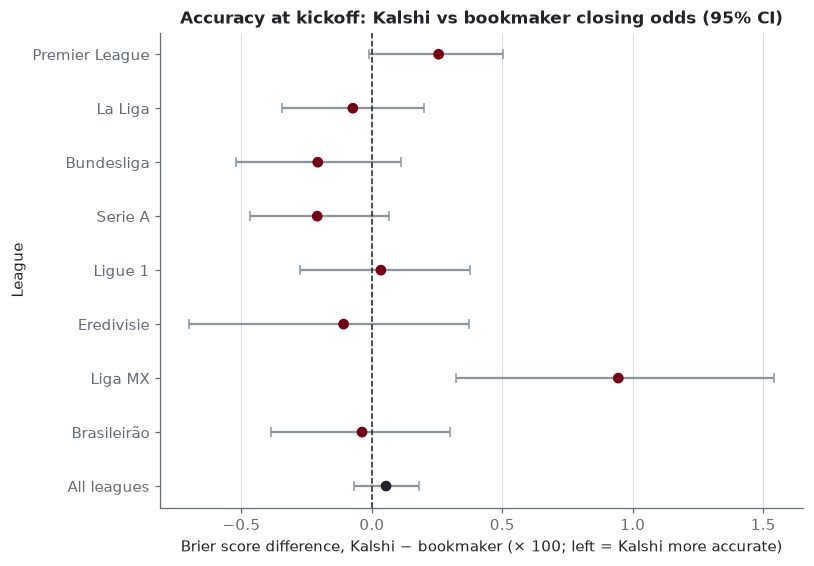

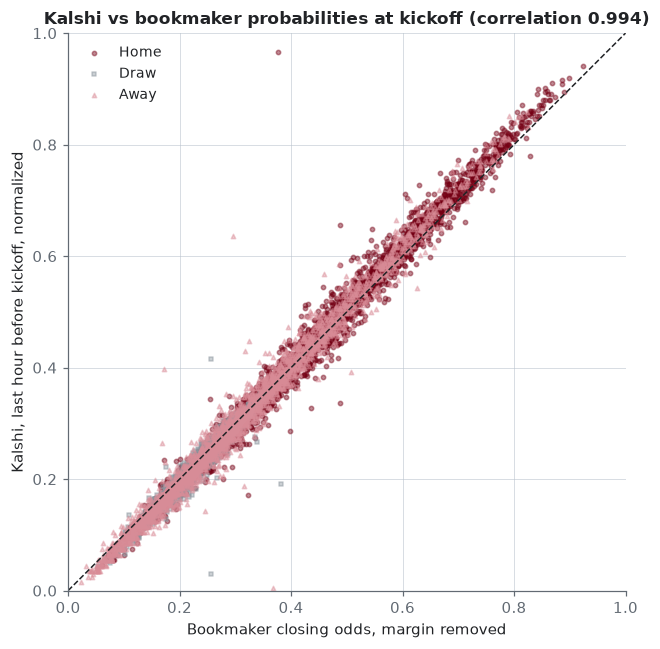

In [6]:
if len(res):
    k = res[(res["timing"] == "at kickoff")].iloc[::-1]
    fig, ax = plt.subplots(figsize=(7.5, 0.45 * len(k) + 1.2))
    y = np.arange(len(k))
    colors = [MIT["black"] if l == "All leagues" else MIT["mit_red"] for l in k["league"]]
    ax.errorbar(100 * k["kalshi_minus_book"], y, xerr=[100 * (k["kalshi_minus_book"] - k["ci_low"]), 100 * (k["ci_high"] - k["kalshi_minus_book"])],
                fmt="none", ecolor=MIT["silver"], capsize=3)
    ax.scatter(100 * k["kalshi_minus_book"], y, color=colors, zorder=3)
    ax.axvline(0, color=MIT["black"], ls="--", lw=1)
    ax.set_yticks(y); ax.set_yticklabels(k["league"]); ax.set_ylabel("League")
    ax.set_xlabel("Brier score difference, Kalshi − bookmaker (× 100; left = Kalshi more accurate)")
    ax.set_title("Accuracy at kickoff: Kalshi vs bookmaker closing odds (95% CI)")
    ax.grid(axis="y", visible=False)
    plt.tight_layout(); save_fig("kalshi_vs_bookmaker_accuracy_by_league"); plt.show()

if close_probs:
    cp = pd.concat(close_probs).reset_index().rename(columns={"level_1": "leg"})
    fig, ax = plt.subplots(figsize=(6, 6))
    for leg, mk_ in zip(LEGS, ["o", "s", "^"]):
        z = cp[cp["leg"] == leg]
        ax.scatter(z["book"], z["kalshi"], s=8, alpha=.45, marker=mk_, color=LEG_COLORS[leg], label=leg.capitalize())
    ax.plot([0, 1], [0, 1], ls="--", color=MIT["black"], lw=1)
    r = np.corrcoef(cp["book"], cp["kalshi"])[0, 1]
    ax.set_title(f"Kalshi vs bookmaker probabilities at kickoff (correlation {r:.3f})")
    ax.set_xlabel("Bookmaker closing odds, margin removed"); ax.set_ylabel("Kalshi, last hour before kickoff, normalized")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend()
    plt.tight_layout(); save_fig("kalshi_vs_bookmaker_scatter"); plt.show()

In [7]:
res.to_csv(OUT / "kalshi_vs_bookmaker_accuracy.csv", index=False)
pd.DataFrame(costs).to_csv(OUT / "kalshi_vs_bookmaker_costs.csv", index=False)
pd.concat({lg: mp for lg, mp in mappings.items()}, names=["league", "code"]).to_csv(OUT / "team_name_mapping.csv")
pd.concat({lg: m[["home_name", "away_name", "date", "gap_days", "realized_outcome"]] for lg, m in matched.items()},
          names=["league", "event_ticker"]).to_csv(OUT / "matched_fixtures.csv")
print("Saved tables and figures in", OUT.resolve())

Saved tables and figures in /Users/ralphnader/Library/CloudStorage/OneDrive-Personal/MIT/Lectures/Fall 2026/Financial Engineering/Projects/Project1/results/bookmakers


6. Could you beat the bookmakers? (betting backtest)

Sections 3–4 show Kalshi and bookmakers forecast about equally well. Here -> ask whether the disagreements btw them are profitable after costs. 2 strats, each using 1 market as the signal and trading in the other:

| Strategy | Signal (probability) | Where you trade | Price paid per \$1 of payout |
|---|---|---|---|
| A. Bet at bookmakers | Kalshi, last hour with all three legs quoted before kickoff (normalized midpoints) | bookmaker closing odds: market average, and best available as an optimistic variant | 1 / odds (includes the bookmaker margin) |
| B. Buy on Kalshi | bookmaker pre-closing odds, margin removed | Kalshi YES at the ask, last pre-kickoff hour | ask + taker fee 0.07·P(1−P) |

No look-ahead: each signal is observed b4 the price it trades at (Kalshi ≈1–1.5 h before kickoff → bookmaker closing odds at kickoff; bookmaker pre-closing odds, collected 1–3 days before → Kalshi's last quote). Closing odds are therefore not used as a signal for Kalshi. Liga MX and the Brasileirão have no pre-closing odds, so B covers 6 leagues.

Rule: bet \$1 on an outcome when the expected return, signal × odds − 1, exceeds a threshold (0, 2, 5 or 10%); "all outcomes" bets every leg as a baseline. Out of sample: the threshold is chosen on the first 70% of matches by kickoff date and evaluated on the last 30%. Returns are per \$1 staked; 95% CIs resample whole matches. Kalshi fees use the large-order rate (no cent rounding), which favours strategy B. This is a historical backtest of market efficiency, not a betting recommendation.

In [8]:
THRESHOLDS = [0.00, 0.02, 0.05, 0.10]
TRAIN_FRAC = 0.7

def long_bets(signal, odds, Y, strategy, lg, kickoff):
    # 1 row per (match, outcome): signal Pr, decimal odds paid, result, expected + realized return
    idx = signal.dropna().index.intersection(odds.dropna().index).intersection(Y.index)
    df = pd.DataFrame({"signal": signal.loc[idx].stack(), "odds": odds.loc[idx].stack(), "y": Y.loc[idx].stack()}).dropna()
    df.index.names = ["event_ticker", "leg"]
    df = df.reset_index()
    df["edge"] = df["signal"] * df["odds"] - 1  # expected return per $1 if signal is right
    df["profit"] = df["y"] * df["odds"] - 1  # realized return per $1
    df["kickoff"] = df["event_ticker"].map(kickoff)
    return df.assign(strategy=strategy, league=LEAGUE_NAMES[lg])

STRATS = {"A_avg": "A. Bet at bookmakers (average closing odds)",
          "A_best": "A. Bet at bookmakers (best closing odds, optimistic)",
          "B": "B. Buy on Kalshi at the ask (+ fees)"}
bets = []
for lg in leagues:
    m, d = matched[lg], data[lg]
    Y = pd.get_dummies(m["realized_outcome"]).reindex(columns=LEGS, fill_value=False).astype(float)
    kick = d["ev"]["kickoff"]
    for key, src in [("A_avg", "market average"), ("A_best", "market maximum")]:
        cols = ODDS_SOURCES[src][0]
        o = m.reindex(columns=cols).astype(float)
        if o.notna().all(axis=1).mean() >= 0.95:
            o.columns = LEGS
            bets.append(long_bets(d["kc"].reindex(m.index), o, Y, key, lg, kick))
    label, cols = choose_source(m, "pre-closing")
    if label is not None:
        P, _ = book_probs(m, cols)
        a = d["asks"].reindex(m.index)
        a = a.where((a > 0) & (a < 1))
        bets.append(long_bets(P, 1 / (a + FEE_RATE * a * (1 - a)), Y, "B", lg, kick))
bets = pd.concat(bets, ignore_index=True)

# 1 chronological cut for all strats: kickoff time splitting the first 70% of matched matches
all_kick = pd.concat([data[lg]["ev"].loc[matched[lg].index, "kickoff"] for lg in leagues])
CUT = all_kick.sort_values().iloc[int(TRAIN_FRAC * len(all_kick))]
bets["sample"] = np.where(bets["kickoff"] < CUT, "train", "test")
print(f"Train: kickoffs before {CUT:%Y-%m-%d}; test: from then on.")

def roi_ci(df):
    # return per $1 staked, w/ a match-level bootstrap CI
    if df.empty:
        return {"bets": 0, "matches": 0, "roi": np.nan, "ci_low": np.nan, "ci_high": np.nan, "hit_rate": np.nan, "avg_odds": np.nan}
    g = df.groupby("event_ticker")["profit"].agg(["sum", "size"])
    picks = np.random.default_rng(SEED).integers(0, len(g), (B, len(g)))
    boot = g["sum"].values[picks].sum(axis=1) / g["size"].values[picks].sum(axis=1)
    return {"bets": len(df), "matches": len(g), "roi": df["profit"].sum() / len(df),
            "ci_low": np.percentile(boot, 2.5), "ci_high": np.percentile(boot, 97.5),
            "hit_rate": df["y"].mean(), "avg_odds": df["odds"].mean()}

rules = [("all outcomes", -np.inf)] + [(f"edge > {t:.0%}", t) for t in THRESHOLDS]
rows = []
for key, name in STRATS.items():
    for rule, t in rules:
        for sample in ["train", "test", "full"]:
            sub = bets[(bets["strategy"] == key) & (bets["edge"] > t)]
            if sample != "full":
                sub = sub[sub["sample"] == sample]
            rows.append({"strategy": name, "rule": rule, "threshold": t, "sample": sample, **roi_ci(sub)})
betting = pd.DataFrame(rows)

# OOS: threshold picked on training matches only (>= 30 bets), then applied to test matches
chosen = []
for name in STRATS.values():
    tr = betting[(betting["strategy"] == name) & (betting["sample"] == "train") & (betting["bets"] >= 30)]
    if tr.empty:
        continue
    best = tr.loc[tr["roi"].idxmax(), "rule"]
    chosen.append(betting[(betting["strategy"] == name) & (betting["rule"] == best) & (betting["sample"] == "test")])
selected = pd.concat(chosen)

show = lambda t: t.assign(**{c: 100 * t[c] for c in ["roi", "ci_low", "ci_high", "hit_rate"]}).drop(columns="threshold").round(2)
print("\nReturn per $1 staked, in % (test = last 30% of matches):")
print(show(betting[betting["sample"] == "test"]).drop(columns="sample").to_string(index=False))
print("\nOut-of-sample, threshold chosen on the training matches:")
print(show(selected).drop(columns="sample").to_string(index=False))
print("\nBy league, full sample, every outcome bet (≈ minus the cost of trading in each market):")
by_lg = bets.groupby(["strategy", "league"]).apply(lambda d: pd.Series(roi_ci(d)), include_groups=False).reset_index()
by_lg["strategy"] = by_lg["strategy"].map(STRATS)
by_lg[["bets", "matches"]] = by_lg[["bets", "matches"]].astype(int)
print(show(by_lg.assign(threshold=0)).to_string(index=False))

Train: kickoffs before 2026-05-17; test: from then on.

Return per $1 staked, in % (test = last 30% of matches):
                                            strategy         rule  bets  matches    roi  ci_low  ci_high  hit_rate  avg_odds
         A. Bet at bookmakers (average closing odds) all outcomes  2988      996  -8.14  -10.93    -5.49     33.33      3.58
         A. Bet at bookmakers (average closing odds)    edge > 0%   166      154   0.89  -18.65    24.75     38.55      3.18
         A. Bet at bookmakers (average closing odds)    edge > 2%    78       75  21.33  -15.08    62.70     41.03      3.56
         A. Bet at bookmakers (average closing odds)    edge > 5%    32       30  81.09   15.71   153.04     50.00      4.21
         A. Bet at bookmakers (average closing odds)   edge > 10%    10        9  80.30  -61.67   204.25     40.00      5.82
A. Bet at bookmakers (best closing odds, optimistic) all outcomes  2988      996  -3.68   -6.75    -0.76     33.33      3.83
A. Bet at bo

                                            strategy         league  bets  matches    roi  ci_low  ci_high  hit_rate  avg_odds
         A. Bet at bookmakers (average closing odds)    Brasileirão  1260      420 -11.49  -14.96    -8.04     33.33      3.37
         A. Bet at bookmakers (average closing odds)     Bundesliga  1155      385  -9.11  -14.00    -4.38     33.33      3.66
         A. Bet at bookmakers (average closing odds)     Eredivisie   960      320  -3.22   -8.85     2.63     33.33      3.76
         A. Bet at bookmakers (average closing odds)        La Liga  1482      494 -10.81  -14.30    -7.03     33.33      3.61
         A. Bet at bookmakers (average closing odds)        Liga MX   987      329  -6.75  -11.22    -2.09     33.33      3.34
         A. Bet at bookmakers (average closing odds)        Ligue 1  1185      395  -8.90  -12.95    -4.95     33.33      3.58
         A. Bet at bookmakers (average closing odds) Premier League  1461      487  -5.32   -8.99    -1.54     

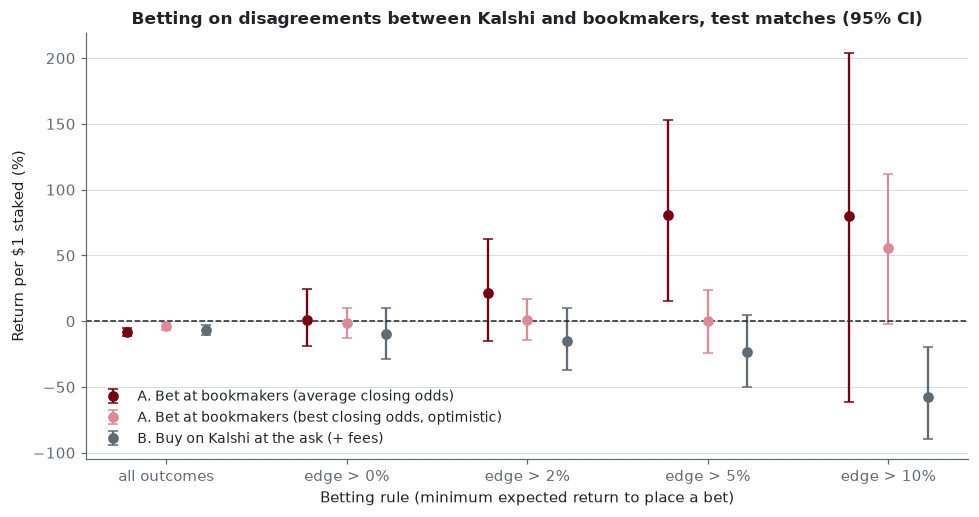

Saved betting backtest tables in /Users/ralphnader/Library/CloudStorage/OneDrive-Personal/MIT/Lectures/Fall 2026/Financial Engineering/Projects/Project1/results/bookmakers


In [9]:
# fig: OOS return by betting threshold, w/ 95% CIs
t = betting[betting["sample"] == "test"].copy()
labels = [r for r, _ in rules]
fig, ax = plt.subplots(figsize=(9, 4.8))
offsets = np.linspace(-0.22, 0.22, len(STRATS))
for (key, name), off, col in zip(STRATS.items(), offsets, [MIT["mit_red"], MIT["light_red"], MIT["dark_gray"]]):
    z = t[t["strategy"] == name].set_index("rule").reindex(labels)
    x = np.arange(len(labels)) + off
    ax.errorbar(x, 100 * z["roi"], yerr=[100 * (z["roi"] - z["ci_low"]), 100 * (z["ci_high"] - z["roi"])],
                fmt="o", color=col, ecolor=col, capsize=3, label=name)
ax.axhline(0, color=MIT["black"], lw=1, ls="--")
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels)
ax.set_xlabel("Betting rule (minimum expected return to place a bet)")
ax.set_ylabel("Return per $1 staked (%)")
ax.set_title("Betting on disagreements between Kalshi and bookmakers, test matches (95% CI)")
ax.grid(axis="x", visible=False)
ax.legend(loc="lower left")
plt.tight_layout(); save_fig("kalshi_vs_bookmaker_betting_backtest"); plt.show()

betting.to_csv(OUT / "betting_backtest_all_rules.csv", index=False)
selected.to_csv(OUT / "betting_backtest_out_of_sample.csv", index=False)
by_lg.to_csv(OUT / "betting_backtest_by_league.csv", index=False)
print("Saved betting backtest tables in", OUT.resolve())